In [4]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# create a synthetic dataset
X, y = make_blobs(random_state=0)
# split data and labels into a training and a test set
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
# instantiate a model and fit it to the training set
logreg = LogisticRegression().fit(X_train, y_train)
# evaluate the model on the test set
print("Test set score: {:.2f}".format(logreg.score(X_test, y_test)))

Test set score: 0.88


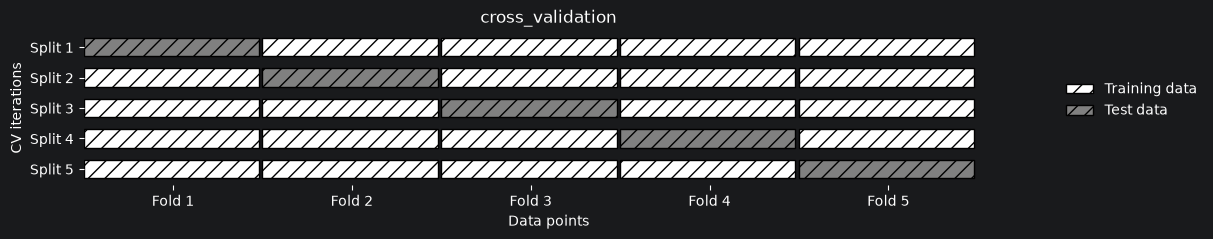

In [5]:
# Representation of 5-fold cross-validation
import mglearn
mglearn.plots.plot_cross_validation()

In [6]:
# Cross validation using cross_val_score()
from sklearn.model_selection import cross_val_score
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression

iris = load_iris()
logreg = LogisticRegression(max_iter=200)

# cv = 3 by default, want at least 5
scores = cross_val_score(logreg, iris.data, iris.target, cv=5)
print("Cross-validation scores: {}".format(scores))
print("Average cross-validation score: {:.2f}".format(scores.mean()))

Cross-validation scores: [0.96666667 1.         0.93333333 0.96666667 1.        ]
Average cross-validation score: 0.97


In [7]:
# Cross validation using cross_validate()
from sklearn.model_selection import cross_validate
import pandas as pd

res = cross_validate(logreg, iris.data, iris.target, cv=5, return_train_score=True)
display(res)

res_df = pd.DataFrame(res)
display(res_df)
print("Mean times and scores:\n", res_df.mean())

{'fit_time': array([0.0155592 , 0.01717281, 0.01294446, 0.0154264 , 0.01410508]),
 'score_time': array([0.00050545, 0.00039744, 0.00045323, 0.00048637, 0.00041771]),
 'test_score': array([0.96666667, 1.        , 0.93333333, 0.96666667, 1.        ]),
 'train_score': array([0.96666667, 0.96666667, 0.98333333, 0.98333333, 0.975     ])}

,fit_time,score_time,test_score,train_score
0,0.015559,0.000505,0.966667,0.966667
1,0.017173,0.000397,1.000000,0.966667
2,0.012944,0.000453,0.933333,0.983333
3,0.015426,0.000486,0.966667,0.983333
4,0.014105,0.000418,1.000000,0.975000


Mean times and scores:
 fit_time       0.015042
score_time     0.000452
test_score     0.973333
train_score    0.975000
dtype: float64


Iris labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


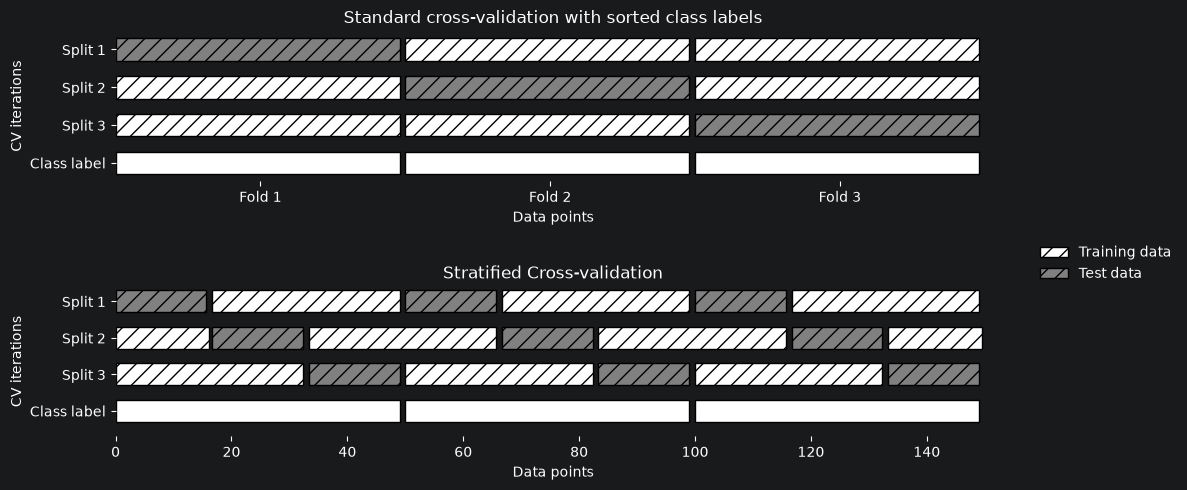

In [8]:
# Example of stratified cross-validation
# Shows why it works since iris dataset is sorted by class label
from sklearn.datasets import load_iris
iris = load_iris()
print("Iris labels:\n{}".format(iris.target))

mglearn.plots.plot_stratified_cross_validation()

In [15]:
# Using kfold splitter in cv parameter for finer control
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5)

print("Cross-validation scores (5 folds):\n{}".format(cross_val_score(logreg, iris.data, iris.target, cv=kfold)))

# Shows why using 3-fold(non-stratified) is bad for iris dataset
kfold = KFold(n_splits=3)
print("Cross-validation scores (3 folds):\n{}".format(cross_val_score(logreg, iris.data, iris.target, cv=kfold)))

# Works better by setting shuffle in kfold
kfold = KFold(n_splits=3, shuffle=True, random_state=0)
print("Cross-validation scores (3 folds, shuffle on):\n{}".format(cross_val_score(logreg, iris.data, iris.target, cv=kfold)))

Cross-validation scores (5 folds):
[1.         1.         0.86666667 0.93333333 0.83333333]
Cross-validation scores (3 folds):
[0. 0. 0.]
Cross-validation scores (3 folds, shuffle on):
[0.98 0.96 0.96]


In [16]:
# Leave-one-out cross-validation
from sklearn.model_selection import LeaveOneOut
loo = LeaveOneOut()
scores = cross_val_score(logreg, iris.data, iris.target, cv=loo)
print("Number of cv iterations ", len(scores))
print("Mean accuracy: {:.2f}".format(scores.mean()))

Number of cv iterations  150
Mean accuracy: 0.97


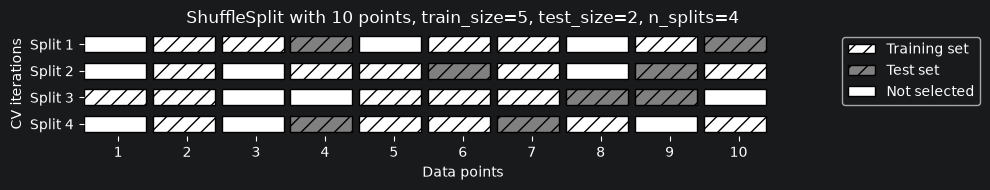

In [18]:
# Shuffle-split cross-validation
mglearn.plots.plot_shuffle_split()

In [19]:
# Shuffle-split cross-validation
from sklearn.model_selection import ShuffleSplit
shuffle_split = ShuffleSplit(test_size=.5, train_size=.5, n_splits=10, random_state=0)
scores = cross_val_score(logreg, iris.data, iris.target, cv=shuffle_split)
print("Cross-validation scores: {}".format(scores))

Cross-validation scores: [0.93333333 0.93333333 0.98666667 0.94666667 0.96       0.94666667
 0.97333333 1.         0.96       0.98666667]


Cross-validation scores: [0.75       0.6        0.66666667]


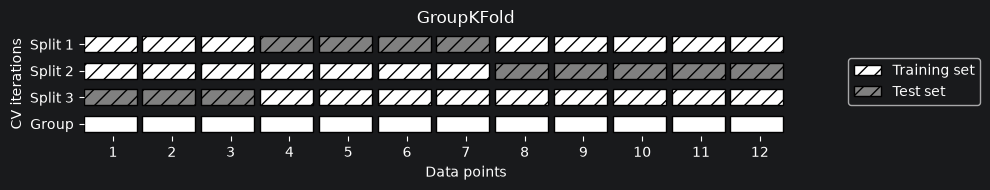

In [22]:
# GroupKFold cross-validation to account for groups of related data
from sklearn.model_selection import GroupKFold
# create synthetic dataset
X, y = make_blobs(n_samples=12, random_state=0)
# assume the first three belong to the same ground, then next 4, etc.
groups = [0, 0, 0, 1, 1, 1, 1, 2, 2, 3, 3, 3]
scores = cross_val_score(logreg, X, y, groups=groups, cv=GroupKFold(n_splits=3))
print("Cross-validation scores: {}".format(scores))

mglearn.plots.plot_group_kfold()

In [23]:
# Simple Grid Search with for loops
from sklearn.svm import SVC
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, random_state=0)
print("Size of training set: {} \t\t Size of test set: {}".format(X_train.shape[0], X_test.shape[0]))

best_score = 0

for gamma in [0.001, 0.01, 0.1, 1, 10, 100]:
    for C in [0.001, 0.01, 0.1, 1, 10, 100]:
        # for each combination, train an SVC
        svm = SVC(gamma=gamma, C=C)
        svm.fit(X_train, y_train)
        # evaluate the SVC on test set
        score = svm.score(X_test, y_test)
        # if score is better, store it and parameters
        if score > best_score:
            best_score = score
            best_parameters = {'C': C, 'gamma': gamma}

print("Best score: {:.2f}".format(best_score))
print("Best parameters: {}".format(best_parameters))

Size of training set: 112 		 Size of test set: 38
Best score: 0.97
Best parameters: {'C': 100, 'gamma': 0.001}


In [26]:
# Threefold-split into training, validation, and test to account
# for overfitting
from sklearn.svm import SVC

# split data into train+validation set and test set
X_trainval, X_test, y_trainval, y_test = train_test_split(iris.data, iris.target, random_state=0)
# split train+validation into seperate sets
X_train, X_valid, y_train, y_valid = train_test_split(X_trainval, y_trainval, random_state=1)
print("Size of training set: {} \t\t Size of validation set: {} \t\t Size of test set: {}".format(X_train.shape[0], X_valid.shape[0], X_test.shape[0]))

best_score = 0

# find parameters using validation set
for gamma in [0.001, 0.01, 0.1, 1, 10, 100]:
    for C in [0.001, 0.01, 0.1, 1, 10, 100]:
        # for each combination, train an SVC
        svm = SVC(gamma=gamma, C=C)
        svm.fit(X_train, y_train)
        # evaluate the SVC on validation set
        score = svm.score(X_valid, y_valid)
        # if score is better, store it and parameters
        if score > best_score:
            best_score = score
            best_parameters = {'C': C, 'gamma': gamma}

# rebuild the model on combined training and validation set,
# and evaluate it on test set
svm = SVC(**best_parameters)
svm.fit(X_trainval, y_trainval)
test_score = svm.score(X_test, y_test)
print("Best score on validation set: {:.2f}".format(best_score))
print("Best parameters: {}".format(best_parameters))
print("Test set score with best parameters: {:.2f}".format(test_score))

Size of training set: 84 		 Size of validation set: 28 		 Size of test set: 38
Best score on validation set: 0.96
Best parameters: {'C': 10, 'gamma': 0.001}
Test set score with best parameters: 0.92


Best score on validation set: 0.97
Best parameters: {'C': 10, 'gamma': 0.1}
Test set score with best parameters: 0.97


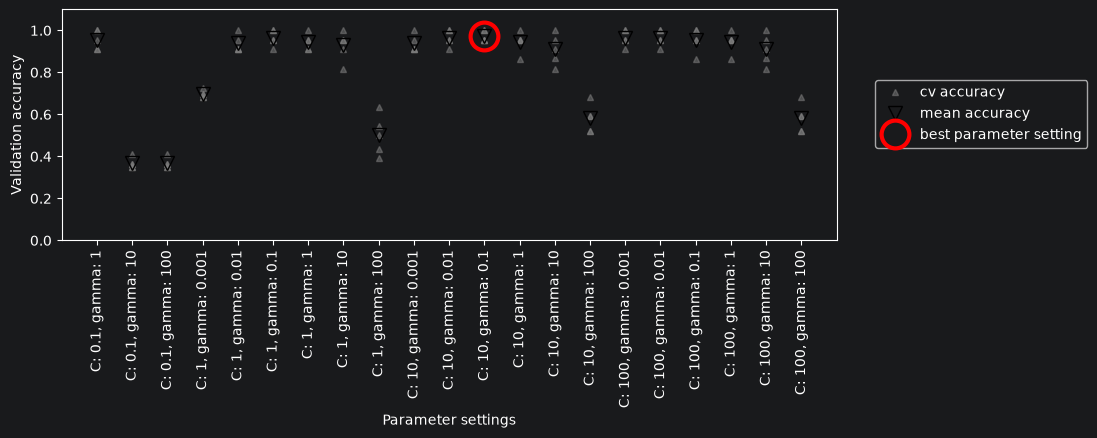

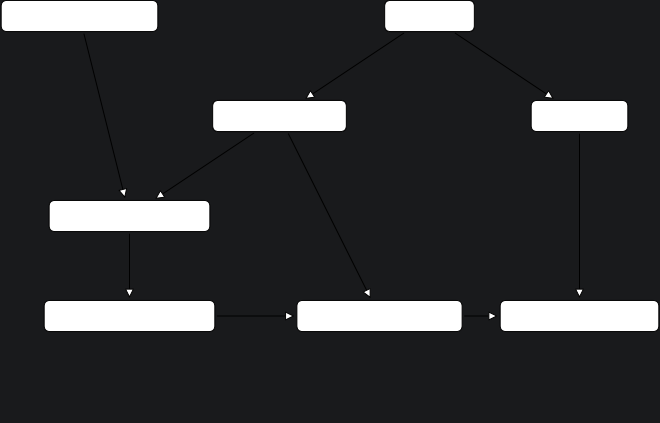

In [31]:
# Using grid-search with cross-validation
import numpy as np

# find parameters using validation set
for gamma in [0.001, 0.01, 0.1, 1, 10, 100]:
    for C in [0.001, 0.01, 0.1, 1, 10, 100]:
        # for each combination, train an SVC
        svm = SVC(gamma=gamma, C=C)
        # perform cross-validation
        scores = cross_val_score(svm, X_trainval, y_trainval, cv=5)
        # compute mean cross-validation accuracy
        score = np.mean(scores)
        # if score is better, store it and parameters
        if score > best_score:
            best_score = score
            best_parameters = {'C': C, 'gamma': gamma}

# rebuild the model on combined training and validation set,
# and evaluate it on test set
svm = SVC(**best_parameters)
svm.fit(X_trainval, y_trainval)
test_score = svm.score(X_test, y_test)
print("Best score on validation set: {:.2f}".format(best_score))
print("Best parameters: {}".format(best_parameters))
print("Test set score with best parameters: {:.2f}".format(test_score))

mglearn.plots.plot_cross_val_selection()
mglearn.plots.plot_grid_search_overview()

In [36]:
# Using GridSearchCV to simplify all the above stuff
from sklearn.model_selection import GridSearchCV

param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100], 'gamma': [0.001, 0.01, 0.1, 1, 10, 100]}
print("Parameter grid:\n{}".format(param_grid))

grid_search = GridSearchCV(SVC(), param_grid, cv=5, return_train_score=True)
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, random_state=0)

grid_search.fit(X_train, y_train)
print("Test set score: {:.2f}".format(grid_search.score(X_test, y_test)))
print("Best parameters: {}".format(grid_search.best_params_))
print("Best cross-validation score: {:.2f}".format(grid_search.best_score_))
# access best estimator
print("Best estimator:\n{}".format(grid_search.best_estimator_))

Parameter grid:
{'C': [0.001, 0.01, 0.1, 1, 10, 100], 'gamma': [0.001, 0.01, 0.1, 1, 10, 100]}
Test set score: 0.97
Best parameters: {'C': 10, 'gamma': 0.1}
Best cross-validation score: 0.97
Best estimator:
SVC(C=10, gamma=0.1)


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_gamma,params,split0_test_score,split1_test_score,split2_test_score,...,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,0.000690,0.000053,0.000531,0.000086,0.001,0.001,"{'C': 0.001, 'gamma': 0.001}",0.347826,0.347826,0.363636,...,0.366403,0.022485,22,0.370787,0.370787,0.366667,0.366667,0.355556,0.366092,0.005581
1,0.000696,0.000103,0.000430,0.000026,0.001,0.010,"{'C': 0.001, 'gamma': 0.01}",0.347826,0.347826,0.363636,...,0.366403,0.022485,22,0.370787,0.370787,0.366667,0.366667,0.355556,0.366092,0.005581
2,0.000645,0.000012,0.000664,0.000354,0.001,0.100,"{'C': 0.001, 'gamma': 0.1}",0.347826,0.347826,0.363636,...,0.366403,0.022485,22,0.370787,0.370787,0.366667,0.366667,0.355556,0.366092,0.005581
3,0.000664,0.000016,0.000417,0.000012,0.001,1.000,"{'C': 0.001, 'gamma': 1}",0.347826,0.347826,0.363636,...,0.366403,0.022485,22,0.370787,0.370787,0.366667,0.366667,0.355556,0.366092,0.005581
4,0.000632,0.000011,0.000414,0.000005,0.001,10.000,"{'C': 0.001, 'gamma': 10}",0.347826,0.347826,0.363636,...,0.366403,0.022485,22,0.370787,0.370787,0.366667,0.366667,0.355556,0.366092,0.005581


TypeError: Only length-1 arrays can be converted to Python scalars

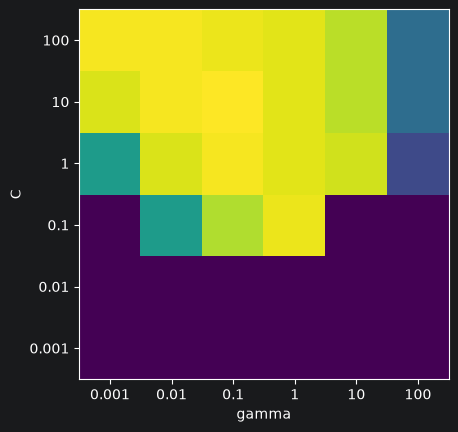

In [51]:
import pandas as pd
# convert results to dataframe
results = pd.DataFrame(grid_search.cv_results_)
# show first 5 rows
display(results.head())

scores = np.array(results.mean_test_score).reshape(6, 6)
mglearn.tools.heatmap(scores, xlabel='gamma', xticklabels=param_grid['gamma'], ylabel='C', yticklabels=param_grid['C'], cmap='viridis')